# Lab 3 - Trenowanie sieci w Keras: klasyfikacja, regresja i regularyzacja

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne)
**Prowadząca:** dr inż. Natalia Piórkowska
**Środowisko:** Google Colab, GPU T4, TensorFlow / Keras 3

## Cel zajęć

Na poprzednich zajęciach (L1, L2) budowaliśmy sieci "od zera" - liczyliśmy gradienty ręcznie, pisaliśmy własne pętle treningowe. Dziś przechodzimy na poziom, na którym pracuje się na co dzień: **wysokopoziomowe API Keras**. Nauczysz się:

1. budować i trenować sieć MLP do **klasyfikacji wieloklasowej** (Fashion-MNIST) z warstwą softmax i stratą `sparse_categorical_crossentropy`,
2. czytać **krzywe uczenia** i diagnozować niedouczenie / przeuczenie,
3. budować sieć do **regresji** (California Housing), poprawnie standaryzować dane (tylko na zbiorze treningowym!) i porównywać się z **baseline'em**,
4. używać **callbacków**: `EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`,
5. porównywać **optymalizatory** (SGD, SGD+momentum, RMSprop, Adam) i dobierać **learning rate**,
6. celowo **przeuczyć** sieć, a potem ją "leczyć": Dropout, regularyzacja L2, BatchNormalization,
7. **zapisywać i wczytywać** modele w formacie `.keras`.

## Efekty uczenia (z karty przedmiotu)

- **UGŁ_W01** - zna metody uczenia sieci (funkcje straty, optymalizatory, regularyzacja).
- **UGŁ_W02** - zna zaawansowane narzędzia DL (Keras, callbacki, zapis modeli - element cyklu życia modelu).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "Dropout zmniejszy różnicę między train a val").
- **UGŁ_U02** - proponuje usprawnienia rozwiązania w oparciu o istniejące biblioteki.

## Powiązanie z wykładem

- **W1** - parametry vs hiperparametry, podział train/val/test, overfitting/underfitting.
- **W2** - warstwa gęsta, aktywacje, softmax, BatchNorm, Dropout.
- **W3** - funkcje straty (MSE, MAE, CCE), optymalizatory (SGD, momentum, RMSProp, Adam), regularyzacja, krzywe uczenia, Keras: `compile` / `fit` / `evaluate`, callbacki. **To główny wykład do tych zajęć.**
- **W4** - metryki klasyfikacji i regresji (zapowiedź - pełna analiza w L5).

## Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | Wstęp, przygotowanie środowiska (sekcja 0) |
| 10-45 min | 1. Klasyfikacja Fashion-MNIST: MLP, softmax, krzywe uczenia (zad. 1.1, 1.2) |
| 45-75 min | 2. Regresja California Housing: standaryzacja, baseline, MSE/MAE (zad. 2.1, 2.2) |
| 75-95 min | 3. Callbacki (zad. 3.1) |
| 95-105 min | **Przerwa (10 min)** |
| 105-130 min | 4. Optymalizatory i learning rate (zad. 4.1, 4.2) |
| 130-160 min | 5. Przeuczenie i regularyzacja: Dropout, L2, BatchNorm (zad. 5.1, 5.2) |
| 160-170 min | 6. Zapis i wczytanie modelu (zad. 6.1) |
| 170-180 min | Pytania kontrolne, podsumowanie, informacje do sprawozdania |

## Wymagania wstępne

- Python, NumPy, matplotlib na poziomie L1-L2.
- Rozumienie: czym jest funkcja straty, gradient, epoka, batch (L1), jak działa MLP i backpropagation (L2).
- Znajomość podziału na zbiór treningowy, walidacyjny i testowy (W1).

## 0. Przygotowanie środowiska

### Włączenie GPU w Colab
W menu wybierz: **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU -> Zapisz**. Po zmianie środowisko zostanie zrestartowane, więc zrób to **przed** uruchomieniem pierwszej komórki.

### Tryb szybki
Zmienna `SZYBKI_TRYB` steruje "budżetem obliczeniowym" notebooka. Gdy `SZYBKI_TRYB = True`:
- używamy tylko części danych (np. 2000 pierwszych obrazów),
- trenujemy tylko przez 2-3 epoki.

Wyniki będą wtedy słabsze, ale cały notebook przejdzie w kilka minut nawet na CPU. **Przełącz na `True`, jeśli pracujesz bez GPU** (np. limit GPU w Colab się wyczerpał) albo chcesz najpierw sprawdzić, czy kod działa. Domyślnie wartość jest odczytywana ze zmiennej środowiskowej `DL_FAST` (na zajęciach w Colab będzie to `False`).

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix

# Tryb szybki: True = mniej danych i epok (praca na CPU / szybki test kodu)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jeśli pracujesz bez GPU

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Backend Keras:", keras.backend.backend())
print("SZYBKI_TRYB =", SZYBKI_TRYB)

TensorFlow: 2.21.0 | Keras: 3.13.2
Backend Keras: tensorflow
SZYBKI_TRYB = False


In [2]:
# Sprawdzenie dostępności GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("Dostępne GPU:", gpus)
else:
    print("Brak GPU - obliczenia na CPU. Rozważ SZYBKI_TRYB = True.")

# Ziarno losowości: ustawia jednocześnie seed dla Pythona, NumPy i TensorFlow.
# Dzięki temu wyniki są (w przybliżeniu) powtarzalne - na GPU drobne różnice i tak mogą wystąpić.
SEED = 42
keras.utils.set_random_seed(SEED)

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Funkcja pomocnicza do rysowania krzywych uczenia

Obiekt `History` zwracany przez `model.fit(...)` ma słownik `history.history`, w którym dla każdej metryki zapisana jest lista wartości z kolejnych epok, np. `loss`, `val_loss`, `accuracy`, `val_accuracy`. Napiszmy funkcję, której będziemy używać przez cały notebook.

In [3]:
def rysuj_historie(historia, metryka="accuracy", tytul=""):
    # Rysuje stratę i wybraną metrykę dla zbioru treningowego i walidacyjnego
    h = historia.history if hasattr(historia, "history") else historia
    epoki = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epoki, h["loss"], "o-", label="train")
    if "val_loss" in h:
        ax[0].plot(epoki, h["val_loss"], "s-", label="walidacja")
    ax[0].set_xlabel("epoka"); ax[0].set_ylabel("strata"); ax[0].set_title(f"{tytul} - strata")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    if metryka in h:
        ax[1].plot(epoki, h[metryka], "o-", label="train")
        if "val_" + metryka in h:
            ax[1].plot(epoki, h["val_" + metryka], "s-", label="walidacja")
        ax[1].set_xlabel("epoka"); ax[1].set_ylabel(metryka); ax[1].set_title(f"{tytul} - {metryka}")
        ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 1. Klasyfikacja wieloklasowa: Fashion-MNIST

### Zbiór danych
Fashion-MNIST to 70 000 obrazów w skali szarości 28x28 przedstawiających 10 kategorii ubrań (60 000 treningowych, 10 000 testowych). Jest trudniejszy niż klasyczny MNIST (cyfry), dlatego lepiej pokazuje różnice między modelami.

### Podział danych - przypomnienie z W1
- **train** - na nim model uczy się parametrów (wag),
- **walidacja (val)** - na nim wybieramy hiperparametry i decydujemy, kiedy przerwać trening,
- **test** - używamy go **raz, na końcu**, do uczciwej oceny. Jeśli patrzymy na test przy dobieraniu hiperparametrów, wynik testowy staje się optymistycznie obciążony.

Keras dostarcza tylko train i test, więc walidację wydzielimy sami z części treningowej.

In [4]:
(x_tr_full, y_tr_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

if SZYBKI_TRYB:
    # w trybie szybkim bierzemy tylko początkowe próbki
    x_tr_full, y_tr_full = x_tr_full[:2000], y_tr_full[:2000]
    x_test, y_test = x_test[:500], y_test[:500]

# Normalizacja do [0, 1]: sieci uczą się znacznie stabilniej na małych wartościach niż na 0..255
x_tr_full = x_tr_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Wydzielamy walidację: ostatnia 1/6 części treningowej (w pełnym trybie 10 000 obrazów)
n_val = len(x_tr_full) // 6
x_train, y_train = x_tr_full[:-n_val], y_tr_full[:-n_val]
x_val, y_val = x_tr_full[-n_val:], y_tr_full[-n_val:]

NAZWY_KLAS = ["T-shirt/top", "Spodnie", "Sweter", "Sukienka", "Płaszcz",
              "Sandał", "Koszula", "Sneaker", "Torba", "Botek"]

print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)
print("zakres wartości:", x_train.min(), "-", x_train.max())
print("liczność klas w train:", np.bincount(y_train, minlength=10))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (50000, 28, 28) val: (10000, 28, 28) test: (10000, 28, 28)
zakres wartości: 0.0 - 1.0
liczność klas w train: [4977 5012 4992 4979 4950 5004 5030 5045 5032 4979]


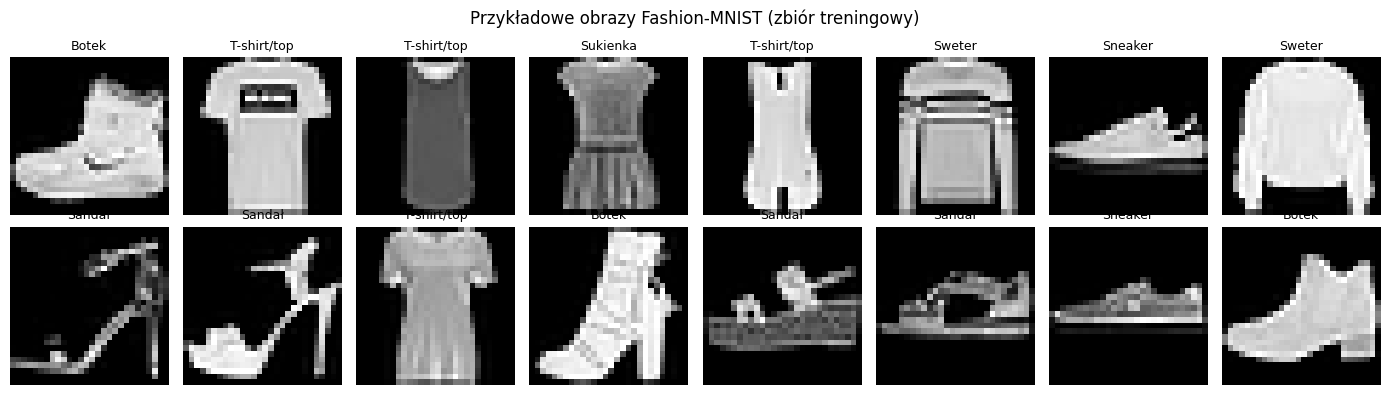

In [5]:
# Podgląd kilku obrazów z etykietami
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(NAZWY_KLAS[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Przykładowe obrazy Fashion-MNIST (zbiór treningowy)")
plt.tight_layout(); plt.show()

### Softmax i entropia krzyżowa

Ostatnia warstwa klasyfikatora na $K$ klas ma $K$ neuronów zwracających liczby rzeczywiste $z_1, \dots, z_K$ (tzw. **logity**). Funkcja **softmax** zamienia je na rozkład prawdopodobieństwa:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad \sum_k p_k = 1.$$

Funkcja straty **kategorialnej entropii krzyżowej** dla jednej próbki z prawdziwą klasą $y$ to

$$L = -\log p_y.$$

Intuicja: jeśli model daje prawdziwej klasie prawdopodobieństwo bliskie 1, strata jest bliska 0; jeśli bliskie 0, strata rośnie do nieskończoności - model jest mocno karany za pewne, ale błędne odpowiedzi.

### `sparse_categorical_crossentropy` vs `categorical_crossentropy`
- `categorical_crossentropy` - etykiety w postaci **one-hot**, np. klasa 3 -> `[0,0,0,1,0,0,0,0,0,0]`,
- `sparse_categorical_crossentropy` - etykiety jako **liczby całkowite** (0..9). Matematycznie to ta sama strata, ale nie trzeba tworzyć macierzy one-hot.

Nasze `y_train` to liczby całkowite, więc użyjemy wersji `sparse_`. **Typowy błąd:** użycie `categorical_crossentropy` z etykietami całkowitymi - Keras zgłosi błąd niezgodności kształtów.

### Ile parametrów ma warstwa gęsta? (W2)
Warstwa `Dense(n_out)` przy wejściu o wymiarze $n_{in}$ ma $n_{in} \cdot n_{out} + n_{out}$ parametrów (wagi + biasy). Dla `Flatten` 28x28 = 784 wejść i 128 neuronów: $784 \cdot 128 + 128 = 100\,480$.

In [6]:
# Model demonstracyjny: najprostszy MLP z jedną warstwą ukrytą
model_demo = keras.Sequential([
    keras.Input(shape=(28, 28)),            # deklaracja kształtu wejścia (bez wymiaru batcha)
    layers.Flatten(),                       # 28x28 -> wektor 784
    layers.Dense(128, activation="relu"),   # warstwa ukryta
    layers.Dense(10, activation="softmax"), # 10 klas -> rozkład prawdopodobieństwa
], name="mlp_demo")

model_demo.summary()   # sprawdź: 100 480 + 1 290 = 101 770 parametrów

Model: "mlp_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### `compile` i `fit`

- `compile(optimizer, loss, metrics)` - konfiguruje trening: czym optymalizujemy, co minimalizujemy i co dodatkowo raportujemy.
- `fit(x, y, epochs, batch_size, validation_data)` - właściwy trening. W każdej epoce model przechodzi raz przez cały zbiór treningowy w porcjach (mini-batchach) po `batch_size` próbek. Po każdej epoce liczone są metryki na zbiorze walidacyjnym.
- `evaluate(x, y)` - liczy stratę i metryki na podanym zbiorze, bez uczenia.

Epoch 1/10
391/391 - 5s - 14ms/step - accuracy: 0.8046 - loss: 0.5727 - val_accuracy: 0.8319 - val_loss: 0.4698
Epoch 2/10
391/391 - 1s - 3ms/step - accuracy: 0.8529 - loss: 0.4165 - val_accuracy: 0.8586 - val_loss: 0.4058
Epoch 3/10
391/391 - 1s - 3ms/step - accuracy: 0.8669 - loss: 0.3758 - val_accuracy: 0.8696 - val_loss: 0.3774
Epoch 4/10
391/391 - 1s - 3ms/step - accuracy: 0.8754 - loss: 0.3483 - val_accuracy: 0.8751 - val_loss: 0.3619
Epoch 5/10
391/391 - 1s - 3ms/step - accuracy: 0.8820 - loss: 0.3279 - val_accuracy: 0.8799 - val_loss: 0.3522
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.8879 - loss: 0.3112 - val_accuracy: 0.8820 - val_loss: 0.3464
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.8921 - loss: 0.2964 - val_accuracy: 0.8799 - val_loss: 0.3441
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.8971 - loss: 0.2843 - val_accuracy: 0.8796 - val_loss: 0.3398
Epoch 9/10
391/391 - 1s - 3ms/step - accuracy: 0.9015 - loss: 0.2731 - val_accuracy: 0.8811 - val_loss: 0.3397


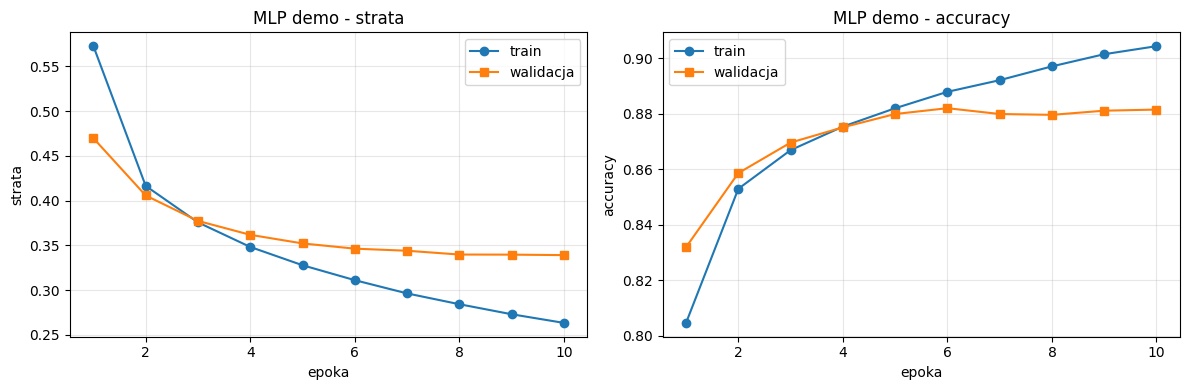

In [7]:
EPOKI_DEMO = 2 if SZYBKI_TRYB else 10

model_demo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
hist_demo = model_demo.fit(
    x_train, y_train,
    epochs=EPOKI_DEMO,
    batch_size=128,
    validation_data=(x_val, y_val),   # walidacja liczona po każdej epoce
    verbose=2,                        # jedna linia na epokę
)
print(f"czas treningu: {time.time() - t0:.1f} s")
rysuj_historie(hist_demo, tytul="MLP demo")

### Jak czytać krzywe uczenia (W3)?

| Obserwacja | Diagnoza | Co zrobić |
|---|---|---|
| strata train i val wysokie, zbliżone | **niedouczenie** (underfitting) | większy model, dłuższy trening, większy lr |
| strata train maleje, val maleje i stabilizuje się | dobre dopasowanie | ewentualnie zatrzymać w minimum val |
| strata train maleje, val zaczyna **rosnąć** | **przeuczenie** (overfitting) | regularyzacja, więcej danych, early stopping |
| strata skacze / rośnie od początku | za duży learning rate, błąd w danych | zmniejszyć lr, sprawdzić dane |

Uwaga: w pierwszych epokach dokładność walidacyjna bywa **wyższa** niż treningowa. To nie błąd - metryki treningowe są uśredniane w trakcie epoki (model na początku epoki był gorszy), a walidacyjne liczone na końcu epoki.

### Zadanie 1.1 - Głębszy MLP

Zbuduj model `model_mlp` (Sequential) o architekturze:
`Input(28,28) -> Flatten -> Dense(256, relu) -> Dense(128, relu) -> Dense(10, softmax)`.

1. Skompiluj go z optymalizatorem Adam (lr = 1e-3), stratą `sparse_categorical_crossentropy` i metryką `accuracy`.
2. Wytrenuj przez `EPOKI_11` epok z `batch_size=128`, z walidacją na `(x_val, y_val)`. Historię zapisz w `hist_mlp`.
3. Narysuj krzywe uczenia funkcją `rysuj_historie`.
4. Oceń model na zbiorze **testowym** (`evaluate`) i wypisz dokładność.
5. Ręcznie policz liczbę parametrów i porównaj z `model_mlp.count_params()`.

**Kryteria sukcesu (pełny tryb, GPU):** dokładność walidacyjna >= 0.87, testowa >= 0.86; liczba parametrów zgadza się z Twoim rachunkiem.

**Wskazówki:** wzorem jest `model_demo` powyżej. Parametry: $784\cdot256+256$, $256\cdot128+128$, $128\cdot10+10$.

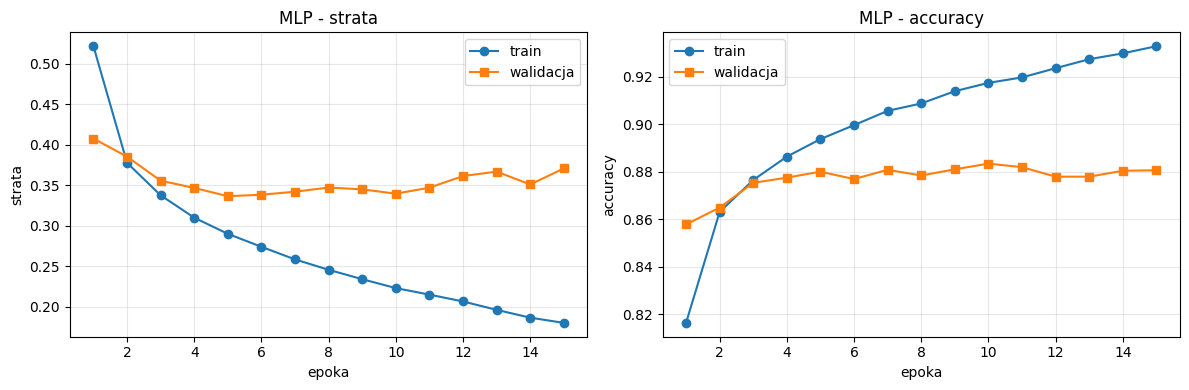

Dokładność testowa: 0.871
Parametry: obliczone 235146, Keras 235146


In [8]:
EPOKI_11 = 2 if SZYBKI_TRYB else 15

model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
hist_mlp = model_mlp.fit(
    x_train, y_train, epochs=EPOKI_11, batch_size=128,
    validation_data=(x_val, y_val), verbose=0,
)
rysuj_historie(hist_mlp, tytul="MLP")
test_loss, test_acc = model_mlp.evaluate(x_test, y_test, verbose=0)
parametry = (784 * 256 + 256) + (256 * 128 + 128) + (128 * 10 + 10)
print(f"Dokładność testowa: {test_acc:.3f}")
print(f"Parametry: obliczone {parametry}, Keras {model_mlp.count_params()}")

### Gdzie model się myli? Macierz pomyłek

Sama dokładność to za mało - chcemy wiedzieć, **które klasy** są mylone. Macierz pomyłek $C$ ma w komórce $C_{ij}$ liczbę próbek o prawdziwej klasie $i$, które model przypisał do klasy $j$. Na przekątnej są poprawne odpowiedzi. (Pełna analiza metryk klasyfikacji: W4 i L5.)

`model.predict(x)` zwraca macierz prawdopodobieństw o kształcie `(n, 10)`; klasę przewidywaną wybieramy przez `argmax` po osi 1.

suma prawdopodobieństw w 1. wierszu: 1.0


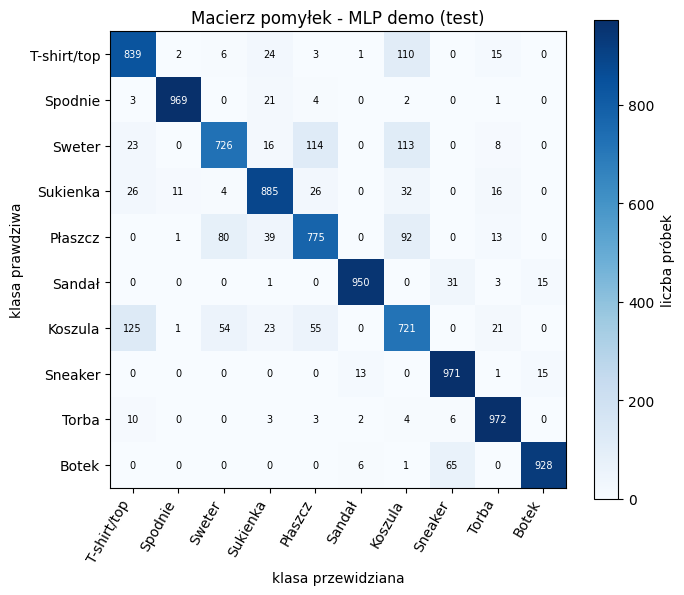

In [9]:
# Demonstracja na model_demo: predykcja i macierz pomyłek
proby = model_demo.predict(x_test, verbose=0)     # (n, 10) prawdopodobieństwa
y_pred_demo = proby.argmax(axis=1)                # klasa o największym prawdopodobieństwie
print("suma prawdopodobieństw w 1. wierszu:", proby[0].sum().round(4))  # softmax -> 1.0

cm = confusion_matrix(y_test, y_pred_demo, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(NAZWY_KLAS, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(NAZWY_KLAS)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa")
ax.set_title("Macierz pomyłek - MLP demo (test)")
plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()

### Zadanie 1.2 - Analiza błędów

Dla modelu `model_mlp` z zadania 1.1:

1. Wyznacz predykcje na zbiorze testowym (`y_pred_mlp`).
2. Policz **dokładność dla każdej klasy osobno** (odsetek poprawnych odpowiedzi wśród próbek danej klasy) i przedstaw ją na wykresie słupkowym z nazwami klas.
3. Znajdź **parę klas najczęściej mylonych** (największy element macierzy pomyłek poza przekątną) i wypisz ją.
4. Pokaż 10 błędnie sklasyfikowanych obrazów z podpisem "prawda / predykcja (prawdopodobieństwo)".

**Kryteria sukcesu:** wykres ma tytuł i opisane osie; potrafisz wyjaśnić, dlaczego właśnie te klasy są mylone.

**Wskazówki:** dokładność klasy $k$ to `cm[k, k] / cm[k].sum()`. Żeby znaleźć maksimum poza przekątną, skopiuj macierz i wyzeruj przekątną (`np.fill_diagonal`), potem `np.unravel_index(m.argmax(), m.shape)`.

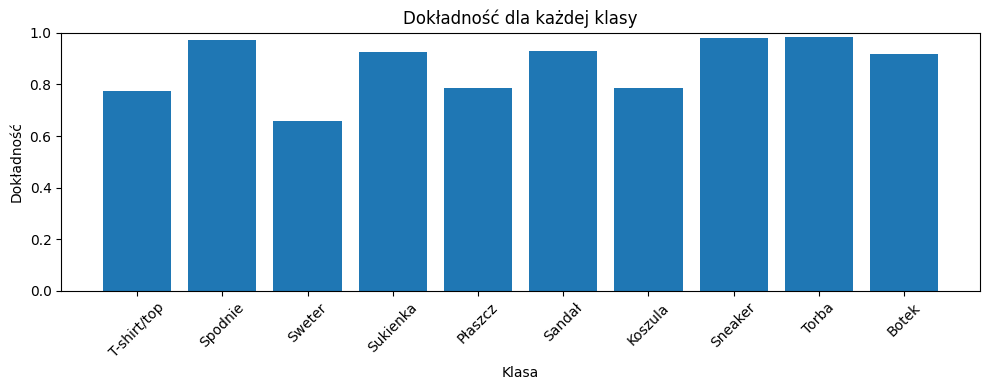

Najczęściej mylone klasy: T-shirt/top -> Koszula (173)


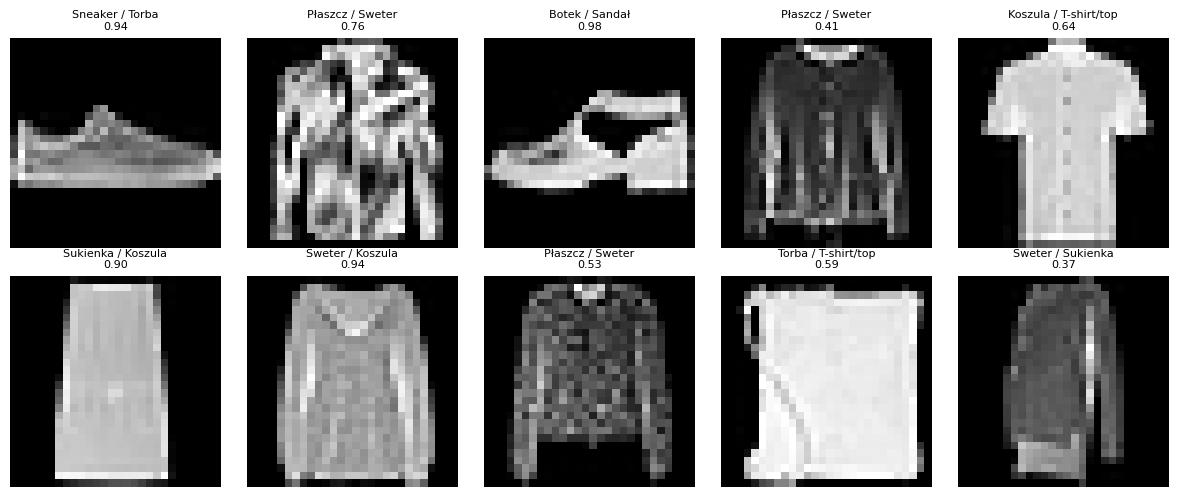

In [10]:
y_pred_mlp = model_mlp.predict(x_test, verbose=0).argmax(axis=1)
cm_mlp = confusion_matrix(y_test, y_pred_mlp, labels=range(10))
dokladnosc_klas = np.diag(cm_mlp) / cm_mlp.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(NAZWY_KLAS, dokladnosc_klas)
ax.set(title="Dokładność dla każdej klasy", xlabel="Klasa", ylabel="Dokładność")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

bledy = cm_mlp.copy()
np.fill_diagonal(bledy, 0)
i_prawda, i_pred = np.unravel_index(np.argmax(bledy), bledy.shape)
print(f"Najczęściej mylone klasy: {NAZWY_KLAS[i_prawda]} -> {NAZWY_KLAS[i_pred]} ({bledy[i_prawda, i_pred]})")

indeksy_bledow = np.flatnonzero(y_pred_mlp != y_test)[:10]
prawdopodobienstwa = model_mlp.predict(x_test[indeksy_bledow], verbose=0).max(axis=1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx, prawd in zip(axes.flat, indeksy_bledow, prawdopodobienstwa):
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(f"{NAZWY_KLAS[y_test[idx]]} / {NAZWY_KLAS[y_pred_mlp[idx]]}\n{prawd:.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Regresja: California Housing

### Zbiór danych
Dane ze spisu powszechnego w Kalifornii (1990): 20 640 dzielnic, 8 cech numerycznych (mediana dochodu, wiek budynków, średnia liczba pokoi, populacja, położenie geograficzne...). Cel: **mediana wartości domu** w dzielnicy, w setkach tysięcy dolarów.

### Co zmienia się względem klasyfikacji?
- warstwa wyjściowa: **1 neuron bez aktywacji** (aktywacja liniowa) - wyjście może być dowolną liczbą rzeczywistą,
- funkcja straty: **MSE** $= \frac{1}{n}\sum_i (y_i - \hat y_i)^2$ lub **MAE** $= \frac{1}{n}\sum_i |y_i - \hat y_i|$ (W3),
- metryki: MAE (w jednostkach celu, łatwa interpretacja), RMSE $= \sqrt{\text{MSE}}$, ewentualnie $R^2$.

MSE silniej karze duże błędy (kwadrat), MAE jest bardziej odporne na wartości odstające. Często trenujemy na MSE (gładki gradient), a raportujemy MAE.

In [11]:
dane = fetch_california_housing(as_frame=True)
df = dane.frame
if SZYBKI_TRYB:
    df = df.iloc[:2000]
print(df.shape)
df.describe().T.round(2)

(20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### Standaryzacja - tylko na zbiorze treningowym!

Cechy mają bardzo różne skale (populacja - tysiące, mediana dochodu - kilka jednostek). Gradient względem wag przy cechach o dużej skali byłby ogromny, a przy małej - znikomy; trening byłby niestabilny. Dlatego standaryzujemy:

$$x' = \frac{x - \mu_{train}}{\sigma_{train}}.$$

**Kluczowe:** średnią $\mu$ i odchylenie $\sigma$ liczymy **wyłącznie na zbiorze treningowym**, a potem tymi samymi wartościami przekształcamy walidację i test. Gdybyśmy dopasowali `StandardScaler` do całych danych, informacja ze zbioru testowego "przeciekłaby" do treningu (**data leakage**, W4) - wynik testowy byłby zbyt optymistyczny. W praktyce produkcyjnej nowe dane też przekształcamy parametrami z treningu, bo przyszłości nie znamy.

Schemat: `scaler.fit(X_train)` -> `scaler.transform(X_train / X_val / X_test)`.

In [12]:
X = df[dane.feature_names].values.astype("float32")
y = df["MedHouseVal"].values.astype("float32")

# Podział 60 / 20 / 20: najpierw odcinamy test, potem z reszty walidację
X_tmp, X_te_r, y_tmp, y_te_r = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_tr_r, X_va_r, y_tr_r, y_va_r = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)

scaler = StandardScaler().fit(X_tr_r)       # fit TYLKO na train
X_tr_s = scaler.transform(X_tr_r)           # transform na wszystkich podzbiorach
X_va_s = scaler.transform(X_va_r)
X_te_s = scaler.transform(X_te_r)

print("train/val/test:", X_tr_s.shape, X_va_s.shape, X_te_s.shape)
print("średnie cech po standaryzacji (train):", X_tr_s.mean(axis=0).round(3))
print("średnie cech po standaryzacji (test): ", X_te_s.mean(axis=0).round(3), "<- nie muszą być 0")

train/val/test: (12384, 8) (4128, 8) (4128, 8)
średnie cech po standaryzacji (train): [ 0.  0. -0.  0. -0.  0.  0.  0.]
średnie cech po standaryzacji (test):  [-0.021  0.014 -0.004  0.011 -0.005 -0.01  -0.026  0.03 ] <- nie muszą być 0


### Baseline - zawsze zaczynaj od punktu odniesienia

Zanim powiesz, że sieć "działa dobrze", porównaj ją z czymś prostym. Najprostszy baseline w regresji: **zawsze przewiduj średnią z treningu**. Jeśli sieć nie jest wyraźnie lepsza, coś jest nie tak (dane, skalowanie, architektura).

In [13]:
# Baseline 0: stała predykcja = średnia celu na zbiorze treningowym
pred_sr = np.full_like(y_te_r, y_tr_r.mean())
mae_sr = mean_absolute_error(y_te_r, pred_sr)
rmse_sr = np.sqrt(mean_squared_error(y_te_r, pred_sr))
print(f"Baseline (średnia): MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}  (jednostka: 100 tys. $)")

Baseline (średnia): MAE = 0.905, RMSE = 1.145  (jednostka: 100 tys. $)


### Zadanie 2.1 - Baseline liniowy

Mocniejszym punktem odniesienia jest **regresja liniowa** (klasyczny model ML, W1).

1. Dopasuj `LinearRegression` ze `sklearn` do `(X_tr_s, y_tr_r)`.
2. Policz MAE i RMSE na zbiorze **testowym**; zapisz w zmiennych `mae_lin`, `rmse_lin`.
3. Wypisz porównanie z baseline'em średniej.

**Kryteria sukcesu (pełny tryb):** MAE regresji liniowej ok. 0.53, wyraźnie mniej niż baseline średniej (ok. 0.9).

In [14]:
model_lin = LinearRegression().fit(X_tr_s, y_tr_r)
pred_lin = model_lin.predict(X_te_s)
mae_lin = mean_absolute_error(y_te_r, pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_te_r, pred_lin))
print(pd.DataFrame({
    "model": ["Średnia", "Regresja liniowa"],
    "MAE": [mae_sr, mae_lin],
    "RMSE": [rmse_sr, rmse_lin],
}).round(3).to_string(index=False))

           model   MAE  RMSE
         Średnia 0.905 1.145
Regresja liniowa 0.533 0.750


### Zadanie 2.2 - Sieć do regresji

1. Zbuduj `model_reg`: `Input(8) -> Dense(64, relu) -> Dense(64, relu) -> Dense(1)` (bez aktywacji na wyjściu!).
2. Skompiluj z Adam (lr = 1e-3), stratą `"mse"` i metryką `"mae"`.
3. Wytrenuj `EPOKI_22` epok, `batch_size=64`, z walidacją `(X_va_s, y_va_r)`. Narysuj krzywe (`metryka="mae"`).
4. Policz MAE i RMSE na teście (`mae_nn`, `rmse_nn`) i zestaw w tabeli (pandas DataFrame) z baseline'ami.
5. Narysuj wykres rozrzutu: wartości prawdziwe vs przewidziane na teście, z linią $y = x$.

**Kryteria sukcesu (pełny tryb):** MAE sieci < 0.42 (wyraźnie lepiej niż liniowa).

**Wskazówki:** `model_reg.predict(X_te_s).ravel()` - wyjście ma kształt `(n, 1)`, spłaszczamy je do `(n,)`. Zapomnienie o `ravel()` przy liczeniu `y - y_pred` daje broadcasting do macierzy `(n, n)` - klasyczny, cichy błąd!

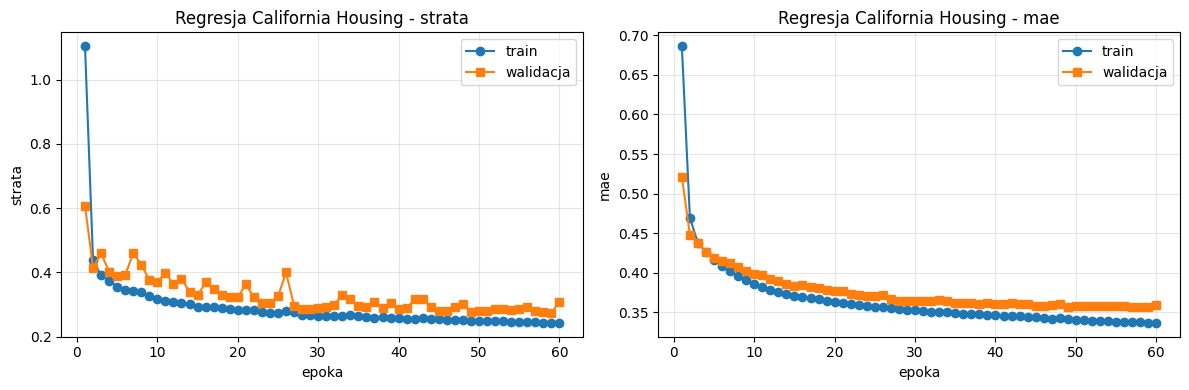

           model   MAE  RMSE
         Średnia 0.905 1.145
Regresja liniowa 0.533 0.750
             MLP 0.352 0.522


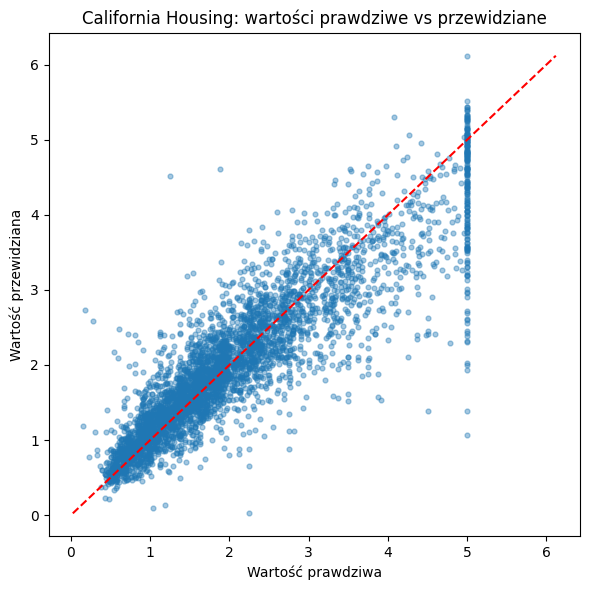

In [15]:
EPOKI_22 = 3 if SZYBKI_TRYB else 60

model_reg = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
])
model_reg.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="mse", metrics=["mae"])
hist_reg = model_reg.fit(
    X_tr_s, y_tr_r, epochs=EPOKI_22, batch_size=64,
    validation_data=(X_va_s, y_va_r), verbose=0,
)
rysuj_historie(hist_reg, metryka="mae", tytul="Regresja California Housing")
pred_nn = model_reg.predict(X_te_s, verbose=0).ravel()
mae_nn = mean_absolute_error(y_te_r, pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_te_r, pred_nn))
print(pd.DataFrame({
    "model": ["Średnia", "Regresja liniowa", "MLP"],
    "MAE": [mae_sr, mae_lin, mae_nn],
    "RMSE": [rmse_sr, rmse_lin, rmse_nn],
}).round(3).to_string(index=False))

plt.figure(figsize=(6, 6))
plt.scatter(y_te_r, pred_nn, alpha=0.4, s=12)
granice = [min(y_te_r.min(), pred_nn.min()), max(y_te_r.max(), pred_nn.max())]
plt.plot(granice, granice, "r--")
plt.xlabel("Wartość prawdziwa")
plt.ylabel("Wartość przewidziana")
plt.title("California Housing: wartości prawdziwe vs przewidziane")
plt.tight_layout()
plt.show()

## 3. Callbacki - automatyzacja treningu

**Callback** to obiekt, którego metody Keras wywołuje w określonych momentach treningu (początek/koniec epoki, batcha, treningu). Najważniejsze wbudowane:

| Callback | Co robi | Kluczowe argumenty |
|---|---|---|
| `EarlyStopping` | przerywa trening, gdy monitorowana metryka przestaje się poprawiać | `monitor="val_loss"`, `patience`, `restore_best_weights=True` |
| `ModelCheckpoint` | zapisuje model (lub wagi) na dysk, np. tylko gdy jest najlepszy | `filepath` (`.keras` lub `.weights.h5`), `save_best_only=True` |
| `ReduceLROnPlateau` | zmniejsza learning rate, gdy metryka stoi w miejscu | `factor` (np. 0.5), `patience`, `min_lr` |

**Early stopping jako regularyzacja (W3):** zatrzymując trening w minimum `val_loss`, nie pozwalamy sieci "zapamiętać" szumu ze zbioru treningowego. `patience` mówi, ile epok bez poprawy tolerujemy (krzywa walidacyjna jest zaszumiona, więc 1 epoka to za mało). `restore_best_weights=True` przywraca wagi z najlepszej epoki - bez tego zostałyby wagi z ostatniej (gorszej) epoki.

**ReduceLROnPlateau - intuicja:** na początku duży krok pozwala szybko zejść w dół funkcji straty; blisko minimum duży krok "przeskakuje" dolinę, więc krok zmniejszamy.

Epoch 10: early stopping
Restoring model weights from the end of the best epoch: 7.
Wykonano 10 z 50 epok; najlepsza epoka (min val_loss): 7


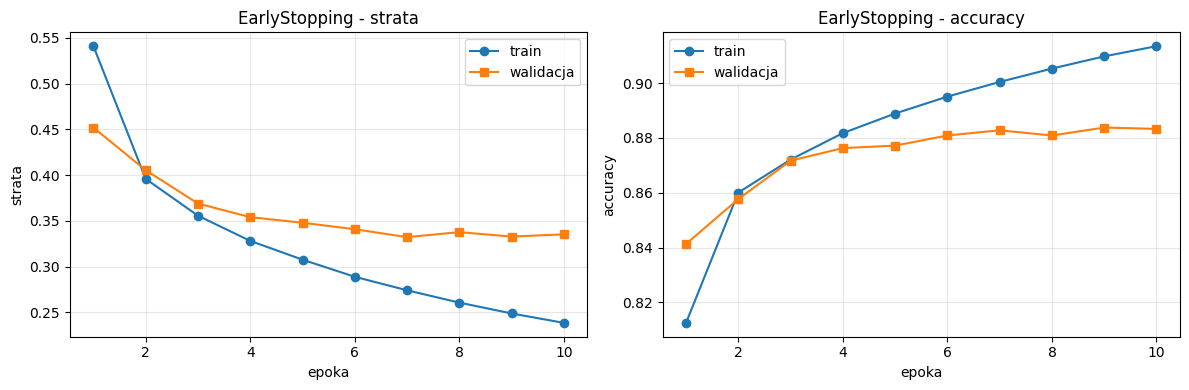

In [16]:
# Demonstracja: EarlyStopping na klasyfikacji Fashion-MNIST z dużą maksymalną liczbą epok
EPOKI_MAX_DEMO = 3 if SZYBKI_TRYB else 50

wczesne_zatrzymanie = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # obserwujemy stratę walidacyjną
    patience=3,                  # 3 epoki bez poprawy -> stop
    restore_best_weights=True,   # przywróć wagi z najlepszej epoki
    verbose=1,
)

model_es = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(256, activation="relu"),
                             layers.Dense(10, activation="softmax")])
model_es.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_es = model_es.fit(x_train, y_train, epochs=EPOKI_MAX_DEMO, batch_size=128,
                       validation_data=(x_val, y_val), callbacks=[wczesne_zatrzymanie], verbose=0)

n_epok = len(hist_es.history["loss"])
najlepsza = int(np.argmin(hist_es.history["val_loss"])) + 1
print(f"Wykonano {n_epok} z {EPOKI_MAX_DEMO} epok; najlepsza epoka (min val_loss): {najlepsza}")
rysuj_historie(hist_es, tytul="EarlyStopping")

### Zadanie 3.1 - Trzy callbacki naraz (regresja)

Wytrenuj **nowy** model o architekturze jak w zad. 2.2 (`model_cb`) na danych California Housing, z maksymalną liczbą epok `EPOKI_MAX_31` i trzema callbackami:

- `EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)`,
- `ModelCheckpoint("najlepszy_reg.keras", monitor="val_loss", save_best_only=True)`,
- `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)`.

Następnie:
1. wypisz, po ilu epokach trening się zatrzymał i która epoka była najlepsza,
2. narysuj, jak zmieniał się learning rate w kolejnych epokach (Keras zapisuje go w `historia.history["learning_rate"]`),
3. wczytaj model z pliku `najlepszy_reg.keras` i policz jego MAE na teście.

**Kryteria sukcesu:** plik `najlepszy_reg.keras` istnieje; w pełnym trybie trening kończy się przed limitem epok, a lr zmalał co najmniej raz; MAE testowe wczytanego modelu <= MAE z zadania 2.2 (lub bardzo zbliżone).

**Wskazówka:** callbacki przekazujemy jako listę: `fit(..., callbacks=[cb1, cb2, cb3])`.

Epoki: 77; najlepsza epoka: 67


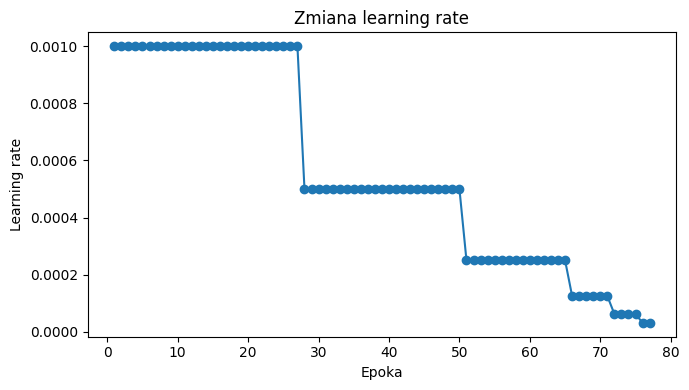

MAE najlepszego modelu: 0.356


In [17]:
EPOKI_MAX_31 = 3 if SZYBKI_TRYB else 200

model_cb = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
])
model_cb.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss="mse", metrics=["mae"])
cb_es = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True,
)
cb_ckpt = keras.callbacks.ModelCheckpoint(
    "najlepszy_reg.keras", monitor="val_loss", save_best_only=True,
)
cb_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5,
)
historia_cb = model_cb.fit(
    X_tr_s, y_tr_r, epochs=EPOKI_MAX_31, batch_size=64,
    validation_data=(X_va_s, y_va_r), callbacks=[cb_es, cb_ckpt, cb_lr],
    verbose=0,
)
najlepsza_epoka_cb = int(np.argmin(historia_cb.history["val_loss"])) + 1
print(f"Epoki: {len(historia_cb.history['loss'])}; najlepsza epoka: {najlepsza_epoka_cb}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(historia_cb.history["learning_rate"]) + 1),
         historia_cb.history["learning_rate"], "o-")
plt.xlabel("Epoka")
plt.ylabel("Learning rate")
plt.title("Zmiana learning rate")
plt.tight_layout()
plt.show()

model_cb_best = keras.models.load_model("najlepszy_reg.keras")
pred_cb = model_cb_best.predict(X_te_s, verbose=0).ravel()
print(f"MAE najlepszego modelu: {mean_absolute_error(y_te_r, pred_cb):.3f}")

---
## Przerwa (10 min)
---

## 4. Optymalizatory i learning rate

Przypomnienie z W3 (wzory dla jednego parametru $w$, gradient $g_t = \nabla_w L$, learning rate $\eta$):

- **SGD:** $w \leftarrow w - \eta\, g_t$. Prosty, ale wolny w "wąskich dolinach" funkcji straty.
- **SGD z momentum:** $v \leftarrow \beta v - \eta g_t,\; w \leftarrow w + v$ (typowo $\beta = 0.9$). Jak kulka toczona po zboczu - "rozpęd" wygładza oscylacje i przyspiesza ruch w spójnym kierunku.
- **RMSprop:** $s \leftarrow \rho s + (1-\rho) g_t^2,\; w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} g_t$. Każdy parametr ma własny, adaptacyjny krok - duże gradienty są tłumione.
- **Adam:** łączy momentum (średnia gradientów $m$) i RMSprop (średnia kwadratów $v$) z korekcją obciążenia: $w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$. Bardzo dobry wybór domyślny (lr = 1e-3).

**Learning rate** to zwykle najważniejszy hiperparametr. Za mały - trening bardzo wolny; za duży - strata oscyluje lub rośnie (rozbieżność, jak w L1).

Do porównań użyjemy funkcji, która za każdym razem buduje **identyczny** model od nowa (te same seedy), zmieniając tylko optymalizator - wtedy porównanie jest uczciwe.

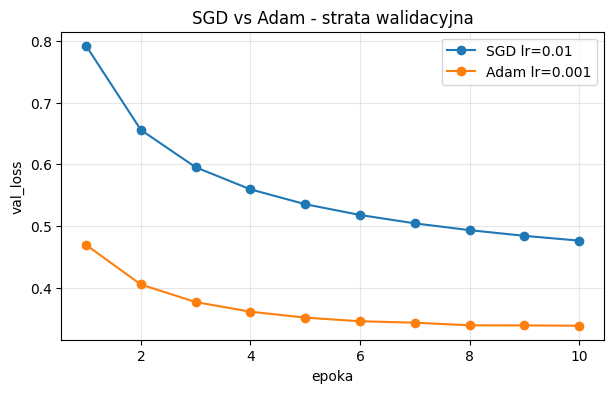

In [18]:
EPOKI_OPT = 2 if SZYBKI_TRYB else 10

def zbuduj_mlp_fashion():
    # Ten sam MLP za każdym razem; seed gwarantuje identyczną inicjalizację wag
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(128, activation="relu"),
                             layers.Dense(10, activation="softmax")])

def trenuj_z_optymalizatorem(optymalizator, epoki=EPOKI_OPT):
    # Trenuje świeży model z podanym optymalizatorem i zwraca słownik historii
    model = zbuduj_mlp_fashion()
    model.compile(optimizer=optymalizator, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(x_train, y_train, epochs=epoki, batch_size=128,
                  validation_data=(x_val, y_val), verbose=0)
    return h.history

# Demonstracja: zwykły SGD vs Adam
wyniki_demo = {
    "SGD lr=0.01": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "Adam lr=0.001": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001)),
}
plt.figure(figsize=(7, 4))
for nazwa, h in wyniki_demo.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], "o-", label=nazwa)
plt.xlabel("epoka"); plt.ylabel("val_loss"); plt.title("SGD vs Adam - strata walidacyjna")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Zadanie 4.1 - Porównanie czterech optymalizatorów

Używając `trenuj_z_optymalizatorem`, porównaj:
- `SGD(learning_rate=0.01)`,
- `SGD(learning_rate=0.01, momentum=0.9)`,
- `RMSprop(learning_rate=0.001)`,
- `Adam(learning_rate=0.001)`.

1. Zapisz historie w słowniku `wyniki_opt` (klucz = nazwa).
2. Narysuj na **jednym** wykresie `val_loss` wszystkich wariantów, a na drugim `val_accuracy`.
3. Utwórz tabelę (DataFrame) z najlepszą `val_accuracy` i epoką, w której ją osiągnięto.

**Kryteria sukcesu:** SGD bez momentum powinien być wyraźnie najwolniejszy; potrafisz to wyjaśnić na podstawie wzorów powyżej.

**Uwaga:** optymalizator to obiekt ze stanem (np. bufor momentum) - dla każdego modelu twórz **nową** instancję, nie używaj tej samej dwa razy.

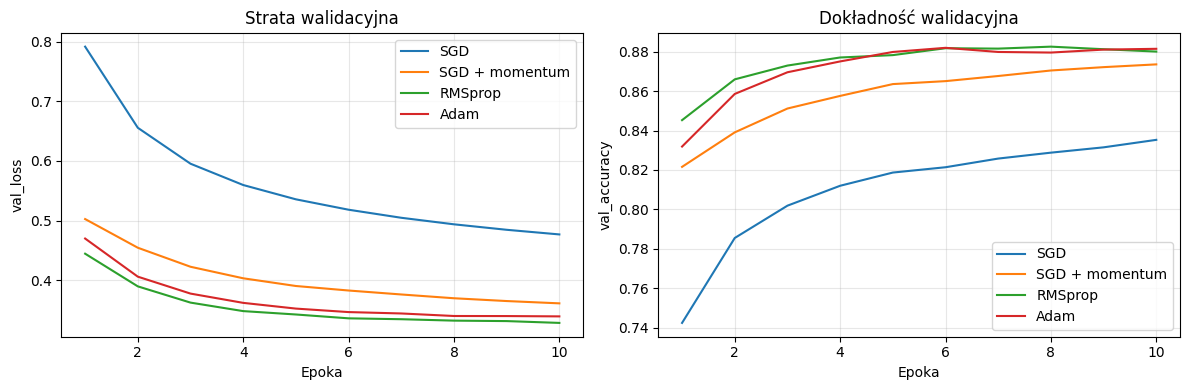

,optymalizator,najlepsza_val_accuracy,epoka
0,SGD,0.8353,10
1,SGD + momentum,0.8736,10
2,RMSprop,0.8826,8
3,Adam,0.8820,6


In [19]:
wyniki_opt = {
    "SGD": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "SGD + momentum": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    "RMSprop": trenuj_z_optymalizatorem(keras.optimizers.RMSprop(learning_rate=0.001)),
    "Adam": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001)),
}
epoki = lambda h: np.arange(1, len(h["val_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nazwa, h in wyniki_opt.items():
    axes[0].plot(epoki(h), h["val_loss"], label=nazwa)
    axes[1].plot(epoki(h), h["val_accuracy"], label=nazwa)
axes[0].set(title="Strata walidacyjna", xlabel="Epoka", ylabel="val_loss")
axes[1].set(title="Dokładność walidacyjna", xlabel="Epoka", ylabel="val_accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

tabela_opt = pd.DataFrame([
    {"optymalizator": nazwa,
     "najlepsza_val_accuracy": max(h["val_accuracy"]),
     "epoka": int(np.argmax(h["val_accuracy"])) + 1}
    for nazwa, h in wyniki_opt.items()
])
display(tabela_opt.round(4))

### Zadanie 4.2 - Wpływ learning rate

Dla optymalizatora Adam sprawdź learning rate z listy `[1e-4, 1e-3, 1e-2, 1e-1]`.

1. Narysuj krzywe `loss` (treningowej!) dla wszystkich wartości na jednym wykresie.
2. Opisz w komórce markdown (2-3 zdania): który lr jest za mały, który za duży i po czym to widać.

**Kryteria sukcesu:** dla lr = 0.1 widać wyraźnie gorszą (wyższą, niestabilną) stratę, dla 1e-4 - powolny spadek.

**Wskazówka:** jeśli strata dla dużego lr robi się `nan`, to też jest wynik - zapisz to w wnioskach (rozbieżność).

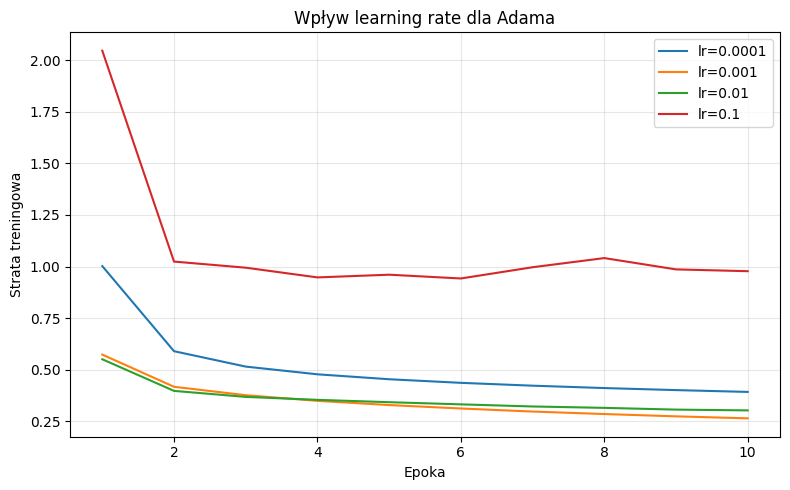

In [20]:
wyniki_lr = {}
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    wyniki_lr[lr] = trenuj_z_optymalizatorem(
        keras.optimizers.Adam(learning_rate=lr)
    )

plt.figure(figsize=(8, 5))
for lr, h in wyniki_lr.items():
    plt.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label=f"lr={lr:g}")
plt.xlabel("Epoka")
plt.ylabel("Strata treningowa")
plt.title("Wpływ learning rate dla Adama")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Wnioski (zad. 4.2):* `lr=1e-4` oznacza najmniejsze kroki aktualizacji, więc jego krzywa powinna opadać wolniej niż dla większych wartości. `lr=0.1` jest zbyt duży, jeśli na wykresie strata jest wyraźnie wyższa, oscyluje, rośnie lub przyjmuje `nan`; spośród pozostałych wartości wybierz tę, dla której strata szybko i stabilnie maleje.

## 5. Celowe przeuczenie i jego "leczenie"

### Przeuczenie (overfitting)
Model o dużej pojemności (dużo parametrów) trenowany na małym zbiorze potrafi "zapamiętać" dane treningowe łącznie z szumem. Objaw: strata treningowa spada niemal do zera, a walidacyjna po pewnym czasie **rośnie**. Żeby wyraźnie to zobaczyć, celowo:
- zmniejszymy zbiór treningowy (do 1000 obrazów),
- użyjemy dużej sieci (3 x 512 neuronów, ok. 930 tys. parametrów),
- będziemy trenować długo.

### Metody regularyzacji (W2, W3)
- **Dropout($p$):** w trakcie treningu każdy neuron jest losowo "wyłączany" z prawdopodobieństwem $p$ (pozostałe są skalowane przez $1/(1-p)$). Sieć nie może polegać na pojedynczych neuronach - uczy się reprezentacji redundantnych. Działa jak uśrednianie wielu "podsieci". W predykcji Dropout jest wyłączony.
- **L2 (weight decay):** do straty dodajemy karę $\lambda \sum w^2$. Gradient kary $2\lambda w$ ściąga wagi w stronę zera - preferowane są "gładsze" funkcje. W Keras: `kernel_regularizer=keras.regularizers.l2(lambda)`.
- **BatchNormalization:** normalizuje aktywacje w mini-batchu do średniej 0 i wariancji 1, potem skaluje uczonymi parametrami $\gamma, \beta$:
  $\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\; y = \gamma \hat{x} + \beta$.
  Głównie **stabilizuje i przyspiesza** trening (pozwala na większy lr); efekt regularyzujący jest uboczny (szum statystyk batcha) i słabszy niż Dropout.
- **Early stopping** - poznaliśmy w sekcji 3.

parametry: 932362


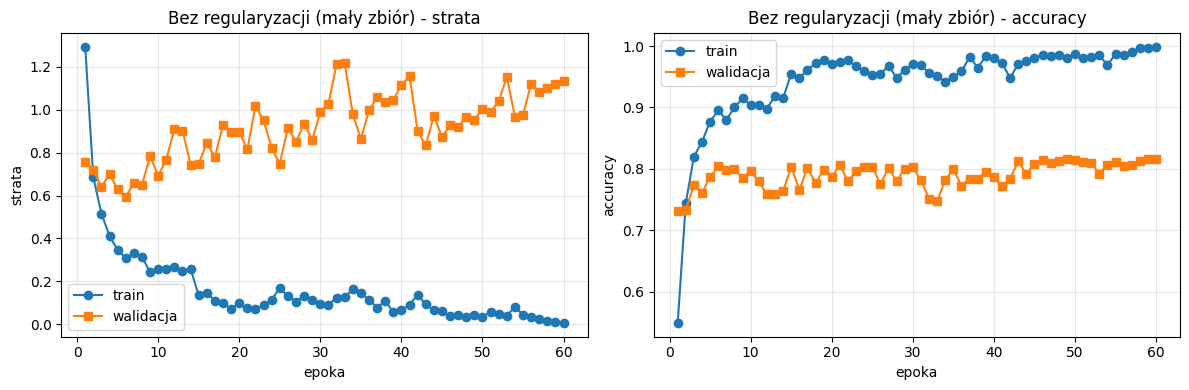

train acc: 0.999, val acc: 0.817, min val_loss w epoce 6


In [21]:
# Mały zbiór treningowy - ułatwia przeuczenie
N_MALY = 500 if SZYBKI_TRYB else 1000
x_maly, y_maly = x_train[:N_MALY], y_train[:N_MALY]
EPOKI_REG = 3 if SZYBKI_TRYB else 60

def zbuduj_przeuczony():
    # Duży MLP bez regularyzacji: 784 -> 512 -> 512 -> 512 -> 10
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    for _ in range(3):
        model.add(layers.Dense(512, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))
    return model

def trenuj_reg(model, epoki=EPOKI_REG):
    # Wspólna procedura treningu dla wszystkich wariantów regularyzacji
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(x_maly, y_maly, epochs=epoki, batch_size=64,
                     validation_data=(x_val, y_val), verbose=0).history

model_over = zbuduj_przeuczony()
print("parametry:", model_over.count_params())
h_over = trenuj_reg(model_over)
rysuj_historie(h_over, tytul="Bez regularyzacji (mały zbiór)")
print(f"train acc: {h_over['accuracy'][-1]:.3f}, val acc: {h_over['val_accuracy'][-1]:.3f}, "
      f"min val_loss w epoce {int(np.argmin(h_over['val_loss'])) + 1}")

### Zadanie 5.1 - Dropout i L2

Napisz funkcję `zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False)`, która buduje taką samą architekturę jak `zbuduj_przeuczony`, ale:
- jeśli `l2 > 0`, każda warstwa ukryta `Dense` ma `kernel_regularizer=keras.regularizers.l2(l2)`,
- jeśli `batchnorm=True`, po każdej warstwie `Dense(512)` (bez aktywacji) dodaj `BatchNormalization()`, a następnie `Activation("relu")`,
- jeśli `dropout > 0`, po każdej warstwie ukrytej (po aktywacji) dodaj `Dropout(dropout)`.

Następnie wytrenuj funkcją `trenuj_reg` dwa warianty i zapisz historie:
- `h_drop` - Dropout 0.5,
- `h_l2` - L2 z $\lambda = 10^{-3}$.

**Kryteria sukcesu (pełny tryb):** dla obu wariantów rosnąca część `val_loss` jest wyraźnie mniejsza niż bez regularyzacji, a różnica między train i val accuracy maleje.

**Wskazówki:** pamiętaj o `keras.utils.set_random_seed(SEED)` na początku funkcji (uczciwe porównanie). Kolejność `Dense -> BatchNorm -> ReLU -> Dropout` to popularny wybór; w literaturze spotyka się też BN po aktywacji.

In [22]:
def zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    regularizer = keras.regularizers.l2(l2) if l2 > 0 else None
    for _ in range(3):
        model.add(layers.Dense(512, activation=None, kernel_regularizer=regularizer))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))
    return model

h_drop = trenuj_reg(zbuduj_regularyzowany(dropout=0.5))
h_l2 = trenuj_reg(zbuduj_regularyzowany(l2=1e-3))

### Zadanie 5.2 - BatchNormalization i zestawienie

1. Wytrenuj wariant z BatchNorm (`h_bn`) oraz wariant łączony BatchNorm + Dropout 0.3 (`h_bn_drop`).
2. Na jednym wykresie narysuj `val_loss` wszystkich pięciu wariantów (bez regularyzacji, Dropout, L2, BN, BN+Dropout).
3. Zbuduj tabelę: najlepsza `val_accuracy`, `val_accuracy` w ostatniej epoce, różnica `accuracy - val_accuracy` w ostatniej epoce (miara przeuczenia).
4. Sformułuj w markdown **hipotezę** przed uruchomieniem (np. "BN poprawi szybkość, ale słabiej ograniczy przeuczenie niż Dropout") i zweryfikuj ją po wynikach (UGŁ_U01).

**Kryteria sukcesu:** tabela i wykres kompletne, hipoteza zweryfikowana wynikami.

*Hipoteza (przed uruchomieniem):* BatchNormalization może ustabilizować trening, ale samodzielnie ograniczy przeuczenie słabiej niż Dropout. Połączenie BN z Dropoutem powinno zmniejszyć lukę między dokładnością treningową i walidacyjną.

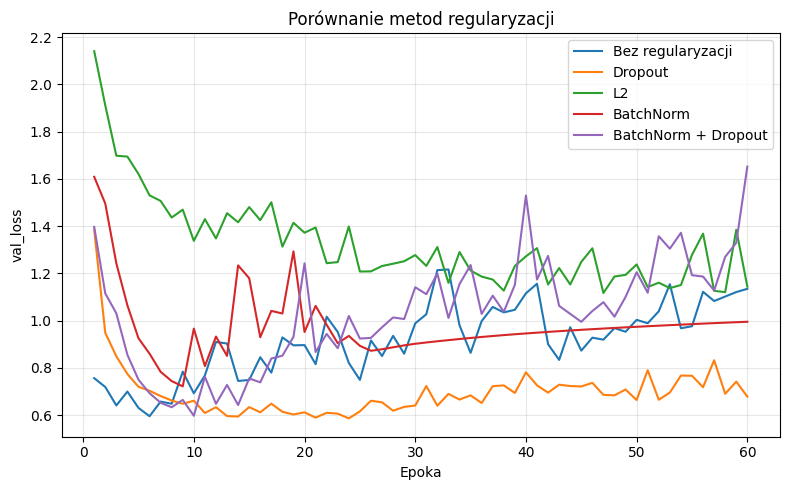

,wariant,najlepsza_val_accuracy,ostatnia_val_accuracy,luka_train_val
0,Bez regularyzacji,0.8165,0.8165,0.1825
1,Dropout,0.8182,0.8182,0.1118
2,L2,0.8117,0.7864,0.1636
3,BatchNorm,0.8126,0.8126,0.1874
4,BatchNorm + Dropout,0.8084,0.7515,0.2435


In [23]:
h_bn = trenuj_reg(zbuduj_regularyzowany(batchnorm=True))
h_bn_drop = trenuj_reg(zbuduj_regularyzowany(batchnorm=True, dropout=0.3))
historie_reg = {
    "Bez regularyzacji": h_over,
    "Dropout": h_drop,
    "L2": h_l2,
    "BatchNorm": h_bn,
    "BatchNorm + Dropout": h_bn_drop,
}
plt.figure(figsize=(8, 5))
for nazwa, h in historie_reg.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label=nazwa)
plt.xlabel("Epoka")
plt.ylabel("val_loss")
plt.title("Porównanie metod regularyzacji")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

tabela_reg = pd.DataFrame([
    {"wariant": nazwa,
     "najlepsza_val_accuracy": max(h["val_accuracy"]),
     "ostatnia_val_accuracy": h["val_accuracy"][-1],
     "luka_train_val": h["accuracy"][-1] - h["val_accuracy"][-1]}
    for nazwa, h in historie_reg.items()
])
display(tabela_reg.round(4))

*Weryfikacja hipotezy:* Dropout najlepiej ograniczył lukę train–val: wyniosła `0.1118`, a najlepsza `val_accuracy` to `0.8182`. Dla BatchNorm luka wyniosła `0.1874` (`val_accuracy=0.8126`), więc sam BatchNorm nie ograniczył przeuczenia lepiej niż Dropout. Wariant łączony nie potwierdził hipotezy o zmniejszeniu luki: osiągnął `0.2435` przy `val_accuracy=0.8084`. Hipoteza została potwierdzona tylko częściowo.

## 6. Zapis i wczytanie modelu

Wytrenowany model to element cyklu życia systemu (W1, W2): trzeba go zapisać, wersjonować, wczytać w innym procesie (np. serwis predykcyjny). W Keras 3:

| Co | Jak | Zawiera |
|---|---|---|
| pełny model | `model.save("plik.keras")`, `keras.models.load_model("plik.keras")` | architekturę, wagi, konfigurację `compile` i stan optymalizatora |
| tylko wagi | `model.save_weights("plik.weights.h5")`, `model.load_weights(...)` | tylko wartości wag - architekturę trzeba odtworzyć w kodzie |

Format `.keras` to archiwum zip (konfiguracja JSON + wagi). Starszy format `.h5` dla pełnych modeli oraz `SavedModel` są w Keras 3 przestarzałe. **Pamiętaj:** w Colab pliki zapisane na dysku maszyny wirtualnej znikają po zakończeniu sesji - aby je zachować, pobierz je lub zapisz na Google Drive.

Zapis wraz ze stanem optymalizatora pozwala **wznowić trening** dokładnie tam, gdzie go przerwano.

In [24]:
# Demonstracja: zapis i wczytanie pełnego modelu
model_demo.save("model_demo.keras")
wczytany = keras.models.load_model("model_demo.keras")

p1 = model_demo.predict(x_test[:100], verbose=0)
p2 = wczytany.predict(x_test[:100], verbose=0)
print("Predykcje identyczne:", np.allclose(p1, p2, atol=1e-6))
print("Rozmiar pliku: %.1f kB" % (os.path.getsize("model_demo.keras") / 1024))
print("Optymalizator wczytanego modelu:", type(wczytany.optimizer).__name__)

Predykcje identyczne: True
Rozmiar pliku: 1215.3 kB
Optymalizator wczytanego modelu: Adam


### Zadanie 6.1 - Zapis wag i wznowienie treningu

1. Zbuduj funkcją `zbuduj_regularyzowany(dropout=0.5)` model, wytrenuj go 2 epoki na `x_maly` (funkcja `trenuj_reg(model, epoki=2)`) i zapisz **same wagi** do `wagi_dropout.weights.h5`.
2. Zbuduj **nowy** model tą samą funkcją, wczytaj do niego wagi i sprawdź (`np.allclose`), że predykcje na `x_test[:100]` są identyczne. Pamiętaj, że Dropout w `predict` jest wyłączony - dlatego wynik jest deterministyczny.
3. Zapisz pierwszy model w całości do `model_dropout.keras`, wczytaj go i **kontynuuj trening** jeszcze 2 epoki przez `fit` (bez ponownego `compile`!). Wypisz `val_accuracy` przed i po.

**Kryteria sukcesu:** oba sprawdzenia `np.allclose` dają `True`; wczytany model trenuje się dalej bez błędu.

**Wskazówka:** nowy model z kroku 2 nie musi być skompilowany, żeby wczytać wagi i wykonać `predict`.

In [26]:
model_dropout = zbuduj_regularyzowany(dropout=0.5)
hist_dropout = trenuj_reg(model_dropout, epoki=2)
val_przed = hist_dropout["val_accuracy"][-1]
model_dropout.save_weights("wagi_dropout.weights.h5")

model_z_wagami = zbuduj_regularyzowany(dropout=0.5)
model_z_wagami.load_weights("wagi_dropout.weights.h5")
p1 = model_dropout.predict(x_test[:100], verbose=0)
p2 = model_z_wagami.predict(x_test[:100], verbose=0)
assert np.allclose(p1, p2, atol=1e-6)

model_dropout.save("model_dropout.keras")
model_wczytany = keras.models.load_model("model_dropout.keras")
historia_dalsza = model_wczytany.fit(
    x_maly, y_maly, epochs=2, batch_size=64,
    validation_data=(x_val, y_val), verbose=0,
)
val_po = historia_dalsza.history["val_accuracy"][-1]
print(f"val_accuracy przed: {val_przed:.4f}; po: {val_po:.4f}")

val_accuracy przed: 0.6442; po: 0.7042


## Pytania kontrolne

1. Dlaczego w ostatniej warstwie klasyfikatora na 10 klas używamy softmax, a w regresji warstwy liniowej? Co by się stało, gdyby w regresji cen domów użyć sigmoidy?
2. Czym różni się `sparse_categorical_crossentropy` od `categorical_crossentropy`? Kiedy używamy której?
3. Dlaczego `StandardScaler` dopasowujemy tylko do zbioru treningowego? Jak nazywa się błąd polegający na dopasowaniu go do całych danych i jakie ma skutki?
4. Ile parametrów ma warstwa `Dense(64)` po wejściu o wymiarze 8? A `BatchNormalization` po niej (ile z nich jest uczonych gradientowo)?
5. Co robi `restore_best_weights=True` w `EarlyStopping` i dlaczego jest ważne?
6. Wyjaśnij, czym Adam różni się od zwykłego SGD. Dlaczego SGD bez momentum uczy się wolniej?
7. Na wykresie strata walidacyjna rośnie od 8. epoki, a treningowa dalej spada. Jak to nazywamy i jakie trzy działania podejmiesz?
8. Jak działa Dropout w trakcie treningu, a jak w predykcji? Dlaczego przeskalowuje się aktywacje przez $1/(1-p)$?

## Podsumowanie - co warto zapamiętać

- Keras: `Sequential` / `Input` -> `compile(optimizer, loss, metrics)` -> `fit(..., validation_data=...)` -> `evaluate` / `predict`.
- **Klasyfikacja:** wyjście `Dense(K, softmax)` + `sparse_categorical_crossentropy` (etykiety całkowite). **Regresja:** wyjście `Dense(1)` liniowe + MSE (raportuj MAE/RMSE).
- **Normalizuj dane;** parametry skalowania dopasowuj **tylko na train** - inaczej wyciek danych.
- Zawsze porównuj z **baseline'em** (średnia, regresja liniowa) - bez tego nie wiesz, czy sieć cokolwiek daje.
- **Krzywe uczenia** to podstawowe narzędzie diagnostyczne: niedouczenie vs przeuczenie.
- **Callbacki:** `EarlyStopping(restore_best_weights=True)`, `ModelCheckpoint(save_best_only=True)`, `ReduceLROnPlateau`.
- **Learning rate** jest najważniejszym hiperparametrem; Adam (1e-3) to dobry punkt startowy, SGD+momentum - solidna alternatywa.
- **Regularyzacja:** Dropout i L2 zmniejszają lukę train-val; BatchNorm głównie stabilizuje trening; najlepsze lekarstwo to więcej danych.
- Zapis: `.keras` (pełny model, wznowienie treningu) lub `.weights.h5` (same wagi).

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, maks. 1,5 strony):

1. **Krzywe uczenia** MLP z zad. 1.1 z krótką diagnozą (w której epoce zaczyna się przeuczenie) oraz dokładność testową.
2. **Tabelę regresji** z zad. 2.2 (średnia / regresja liniowa / MLP; MAE i RMSE) i wykres y vs y_pred z komentarzem o obciętych wartościach.
3. **Porównanie optymalizatorów** (zad. 4.1) - wykres i 2-3 zdania interpretacji.
4. **Tabelę regularyzacji** z zad. 5.2 wraz z **hipotezą i jej weryfikacją** (UGŁ_U01).
5. Jedną **propozycję usprawnienia** (UGŁ_U02), np. inny harmonogram lr, AdamW, augmentacja, inna architektura - z uzasadnieniem.